# EXPT NO. 7 — Implementation of a Simple Autoencoder for Dimensionality Reduction and Feature Learning

**Name:** Midhun P.  
**Roll Number:** 24BAD069  
**Dataset:** MNIST handwritten digits  




## Part A — Dataset Preparation
Load MNIST, inspect the data, normalize pixel values to [0, 1], flatten images for a Dense Autoencoder, split into training/testing data, and display original samples.

Student: Midhun P.
Roll Number: 24BAD069
TensorFlow version: 2.21.0
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images shape: (60000, 28, 28)
Testing images shape: (10000, 28, 28)
Training data type: uint8
Pixel range before normalization: 0 to 255
Flattened training shape: (60000, 784)
Flattened testing shape: (10000, 784)
Pixel range after normalization: 0.0 to 1.0


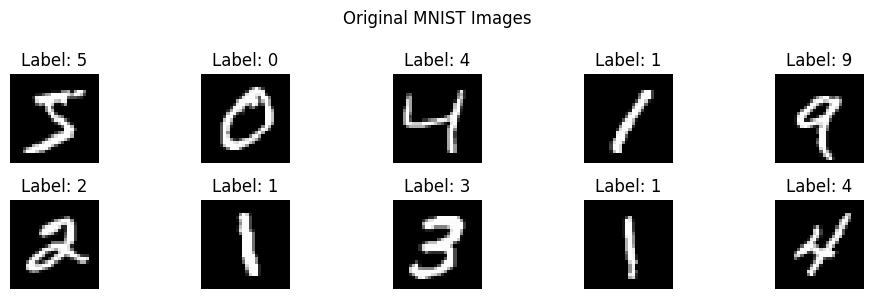

In [3]:
# Student details
NAME = "Midhun P."
ROLL_NUMBER = "24BAD069"

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, Model

print("Student:", NAME)
print("Roll Number:", ROLL_NUMBER)
print("TensorFlow version:", tf.__version__)

# Load MNIST (60,000 training and 10,000 test grayscale images, each 28x28)
(x_train_img, y_train), (x_test_img, y_test) = tf.keras.datasets.mnist.load_data()

print("Training images shape:", x_train_img.shape)
print("Testing images shape:", x_test_img.shape)
print("Training data type:", x_train_img.dtype)
print("Pixel range before normalization:", x_train_img.min(), "to", x_train_img.max())

# Normalize pixel values from 0–255 to 0–1
x_train_img = x_train_img.astype("float32") / 255.0
x_test_img = x_test_img.astype("float32") / 255.0

# Flatten 28x28 images to 784-dimensional vectors for a Dense Autoencoder
input_dim = 28 * 28
x_train = x_train_img.reshape((-1, input_dim))
x_test = x_test_img.reshape((-1, input_dim))

print("Flattened training shape:", x_train.shape)
print("Flattened testing shape:", x_test.shape)
print("Pixel range after normalization:", x_train.min(), "to", x_train.max())

# Display sample original images
plt.figure(figsize=(10, 3))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train_img[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")
plt.suptitle("Original MNIST Images")
plt.tight_layout()
plt.show()

## Part B — Implementing the Autoencoder Model
The encoder compresses 784 input values into a 32-value latent representation. The decoder reconstructs the 784 pixel values. ReLU is used in hidden layers and sigmoid in the output layer because pixels are normalized to [0, 1].

In [4]:
# Define encoder, bottleneck, and decoder
latent_dim = 32

input_layer = layers.Input(shape=(input_dim,), name="input_image")
encoded = layers.Dense(128, activation="relu", name="encoder_hidden")(input_layer)
latent = layers.Dense(latent_dim, activation="relu", name="bottleneck")(encoded)

decoded = layers.Dense(128, activation="relu", name="decoder_hidden")(latent)
output_layer = layers.Dense(input_dim, activation="sigmoid", name="reconstructed_image")(decoded)

autoencoder = Model(input_layer, output_layer, name="simple_autoencoder")
encoder = Model(input_layer, latent, name="encoder")

# Decoder model: takes a latent vector and reconstructs an image vector
latent_input = layers.Input(shape=(latent_dim,), name="latent_input")
decoder_hidden = autoencoder.get_layer("decoder_hidden")(latent_input)
decoder_output = autoencoder.get_layer("reconstructed_image")(decoder_hidden)
decoder = Model(latent_input, decoder_output, name="decoder")

autoencoder.compile(optimizer="adam", loss="mse")
autoencoder.summary()
print("\nEncoder summary:")
encoder.summary()
print("\nDecoder summary:")
decoder.summary()

Model: "simple_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_hidden (Dense)          │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (Dense)              │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_hidden (Dense)          │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstructed_image (Dense)     │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209,968 (820.19 KB)

 Trainable params: 209,968 (820.19 KB)

 Non-trainable params: 0 (0.00 B)


Encoder summary:


... (7 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ latent_input (InputLayer)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_hidden (Dense)          │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstructed_image (Dense)     │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 105,360 (411.56 KB)

 Trainable params: 105,360 (411.56 KB)

 Non-trainable params: 0 (0.00 B)

## Part C — Model Training and Performance Evaluation
Train using each image as both input and target. Track training and validation loss, evaluate on test data, calculate reconstruction MSE, plot the loss curve, and compare original and reconstructed images.

In [5]:
# Train the model. Validation data is held out from the training set.
history = autoencoder.fit(
    x_train, x_train,
    epochs=10,
    batch_size=256,
    shuffle=True,
    validation_split=0.1,
    verbose=1
)

Epoch 1/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - loss: 0.0625 - val_loss: 0.0352
Epoch 2/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.0283 - val_loss: 0.0231
Epoch 3/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.0207 - val_loss: 0.0185
Epoch 4/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.0173 - val_loss: 0.0161
Epoch 5/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.0155 - val_loss: 0.0149
Epoch 6/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.0145 - val_loss: 0.0139
Epoch 7/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.0136 - val_loss: 0.0131
Epoch 8/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.0129 - val_loss: 0.0125
Epoch 9/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.0124 - val_loss: 0.0121
Epoch 10/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 0.0120 - val_loss: 0.0118


In [6]:
# Record final training and validation loss
final_train_loss = history.history["loss"][-1]
final_val_loss = history.history["val_loss"][-1]

test_loss = autoencoder.evaluate(x_test, x_test, verbose=0)
reconstructed_test = autoencoder.predict(x_test, verbose=0)
test_mse = float(np.mean(np.square(x_test - reconstructed_test)))

print(f"Final training loss (MSE): {final_train_loss:.6f}")
print(f"Final validation loss (MSE): {final_val_loss:.6f}")
print(f"Test reconstruction loss (MSE): {test_loss:.6f}")
print(f"Calculated test reconstruction MSE: {test_mse:.6f}")

Final training loss (MSE): 0.011997
Final validation loss (MSE): 0.011774
Test reconstruction loss (MSE): 0.011418
Calculated test reconstruction MSE: 0.011418


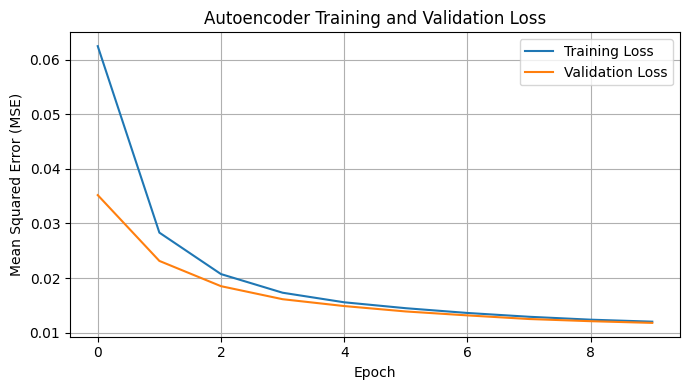

In [7]:
# Plot training and validation loss against epochs
plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("Autoencoder Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

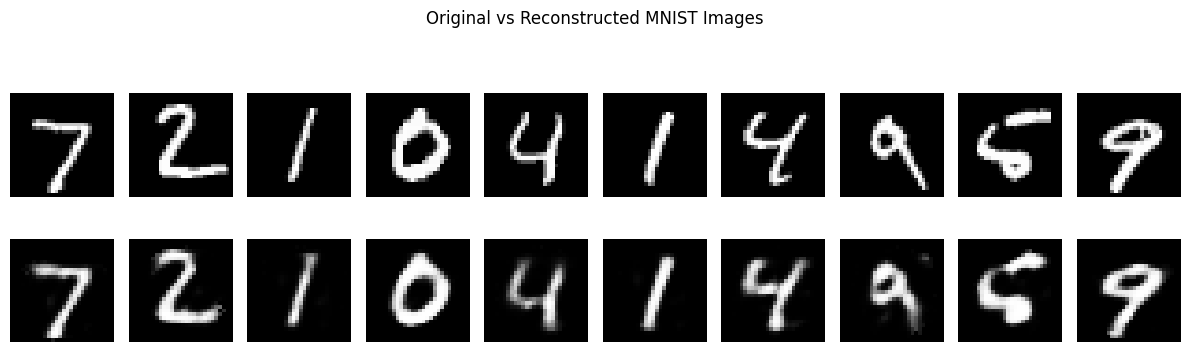

In [8]:
# Compare original images with reconstructed images
n = 10
decoded_images = reconstructed_test[:n].reshape(-1, 28, 28)

plt.figure(figsize=(12, 4))
for i in range(n):
    # Original
    plt.subplot(2, n, i + 1)
    plt.imshow(x_test_img[i], cmap="gray")
    plt.axis("off")
    if i == 0:
        plt.ylabel("Original", fontsize=10)

    # Reconstruction
    plt.subplot(2, n, n + i + 1)
    plt.imshow(decoded_images[i], cmap="gray")
    plt.axis("off")
    if i == 0:
        plt.ylabel("Reconstructed", fontsize=10)

plt.suptitle("Original vs Reconstructed MNIST Images")
plt.tight_layout()
plt.show()

## Part D — Dimensionality Reduction and Feature Visualization
Extract latent representations with the trained encoder, compare original and compressed dimensions, visualize a sample of latent features, and reconstruct selected samples using the decoder.

In [9]:
# Extract latent-space representations
latent_train_sample = encoder.predict(x_test[:2000], verbose=0)
print("Original feature dimensions per image:", input_dim)
print("Compressed latent dimensions per image:", latent_dim)
print("Original test data shape:", x_test.shape)
print("Latent representation shape (first 2000 test images):", latent_train_sample.shape)
print(f"Dimensionality reduced from {input_dim} to {latent_dim} values per image.")
print(f"Compression in number of values: {(1 - latent_dim / input_dim) * 100:.2f}%")

Original feature dimensions per image: 784
Compressed latent dimensions per image: 32
Original test data shape: (10000, 784)
Latent representation shape (first 2000 test images): (2000, 32)
Dimensionality reduced from 784 to 32 values per image.
Compression in number of values: 95.92%


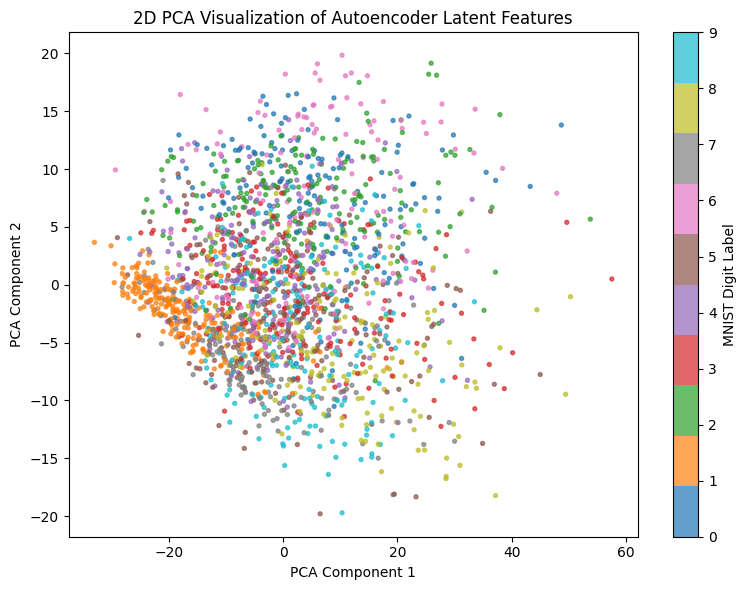

In [10]:
# Visualize the latent representations using PCA to project them to 2D
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
latent_2d = pca.fit_transform(latent_train_sample)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    latent_2d[:, 0], latent_2d[:, 1],
    c=y_test[:2000], cmap="tab10", s=8, alpha=0.7
)
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("2D PCA Visualization of Autoencoder Latent Features")
plt.colorbar(scatter, label="MNIST Digit Label")
plt.tight_layout()
plt.show()

Selected sample latent shape: (8, 32)
Selected sample reconstruction shape: (8, 784)


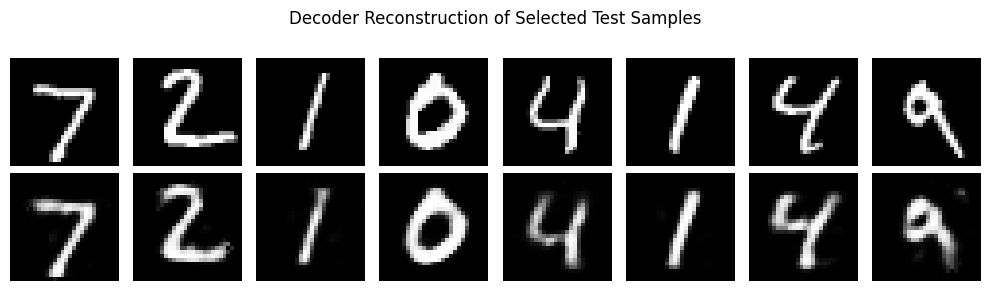

In [11]:
# Reconstruct selected samples directly through encoder and decoder
sample_count = 8
sample_original = x_test[:sample_count]
sample_latent = encoder.predict(sample_original, verbose=0)
sample_reconstructed = decoder.predict(sample_latent, verbose=0)

print("Selected sample latent shape:", sample_latent.shape)
print("Selected sample reconstruction shape:", sample_reconstructed.shape)

plt.figure(figsize=(10, 3))
for i in range(sample_count):
    plt.subplot(2, sample_count, i + 1)
    plt.imshow(sample_original[i].reshape(28, 28), cmap="gray")
    plt.axis("off")
    if i == 0:
        plt.ylabel("Original")

    plt.subplot(2, sample_count, sample_count + i + 1)
    plt.imshow(sample_reconstructed[i].reshape(28, 28), cmap="gray")
    plt.axis("off")
    if i == 0:
        plt.ylabel("Reconstructed")

plt.suptitle("Decoder Reconstruction of Selected Test Samples")
plt.tight_layout()
plt.show()

## Observations and Result

Based on the execution of our Autoencoder model, here are the observations and results:

### Observations
1. **Data Dimensions & Normalization:**
   - The original MNIST dataset consists of 28×28 pixel grayscale images (784 features).
   - All pixel values were successfully normalized to the range `[0.0, 1.0]` before training.
2. **Architecture & Compression:**
   - The encoder successfully compressed each 784-dimensional image down to a 32-dimensional latent representation.
   - This represents a dimensionality reduction and value compression of **95.92%**.
   - The decoder successfully reconstructed the 784-dimensional vector from this compressed 32-dimensional bottleneck vector.
3. **Loss Trend:**
   - Both the Training and Validation Loss (Mean Squared Error) decreased steadily over 10 epochs (Training Loss: `0.011997`, Validation Loss: `0.011774`), showing stable learning without overfitting.
4. **Qualitative Reconstruction:**
   - Reconstructed digits printed in the comparison plots clearly resemble the originals. Although minor details and sharpness are lost due to compression, the digit class remains highly recognizable.
5. **PCA Feature Space:**
   - Projecting the 32-dimensional latent vectors onto 2D using PCA reveals structured clusters where digits of the same label naturally group together.

### Result
- **Final Training Loss (MSE):** `0.011997`
- **Final Validation Loss (MSE):** `0.011774`
- **Test Reconstruction Loss (MSE):** `0.011418`

The simple Autoencoder has been successfully implemented, trained, and evaluated. It effectively extracts robust low-dimensional latent features from the MNIST dataset while maintaining reconstructive capability.